# Bank Term-Deposit Campaign: Propensity Model & Targeting Strategy

**Business problem.** A retail bank runs outbound phone campaigns to sell a term deposit (similar to an FD). Only about **11% of calls convert**, so most calls cost money and annoy customers who were never going to buy.

**Goal.** Use customer, campaign and macro-economic data to:
1. Find **which segments, channels and timing** drive conversion (descriptive analytics)
2. Build a **propensity model** that scores each customer's likelihood to subscribe (predictive analytics)
3. Turn the score into a **targeting strategy**: who to call, and what that does to campaign profit

**Data.** UCI Bank Marketing dataset (`bank-additional-full.csv`): 41,188 calls made by a Portuguese bank, May 2008 to Nov 2010, with 20 input features and the outcome `y` (subscribed yes/no).
Source: Moro, Cortez & Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, Decision Support Systems.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.width", 120)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9893"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.axisbelow": True,
                     "axes.edgecolor": "#b5b3ad", "font.size": 10})

df = pd.read_csv("data/bank-additional-full.csv", sep=";")
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Data quality checks

In [2]:
print("Missing values (NaN):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
unknowns = (df.select_dtypes("object") == "unknown").sum()
print("\n'unknown' values by column:\n", unknowns[unknowns > 0].sort_values(ascending=False))
print("\npdays == 999 (never contacted before):", f"{(df.pdays == 999).mean():.1%}")

Missing values (NaN): 0
Duplicate rows: 12

'unknown' values by column:
 default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

pdays == 999 (never contacted before): 96.3%


**Decisions:**
- Drop the exact duplicate rows.
- Keep `unknown` as its own category: whether a customer refused to share information can itself be informative.
- `pdays = 999` is a code meaning "never contacted", not a real number. Convert it to a flag `prev_contacted`.
- **Drop `duration` (call length).** It is only known *after* the call ends, and a 0-second call is always a "no". Using it would leak the answer into the model and make it useless for deciding *whom to call*. This is the most common mistake people make with this dataset.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
df["target"] = (df["y"] == "yes").astype(int)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df["age_band"] = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120],
                        labels=["Up to 25", "26-35", "36-45", "46-55", "56-65", "65+"])
base_rate = df["target"].mean()
print(f"Rows after de-dup: {len(df):,} | Overall conversion rate: {base_rate:.2%}")

Rows after de-dup: 41,176 | Overall conversion rate: 11.27%


## 2. Exploratory analysis: where does conversion come from?

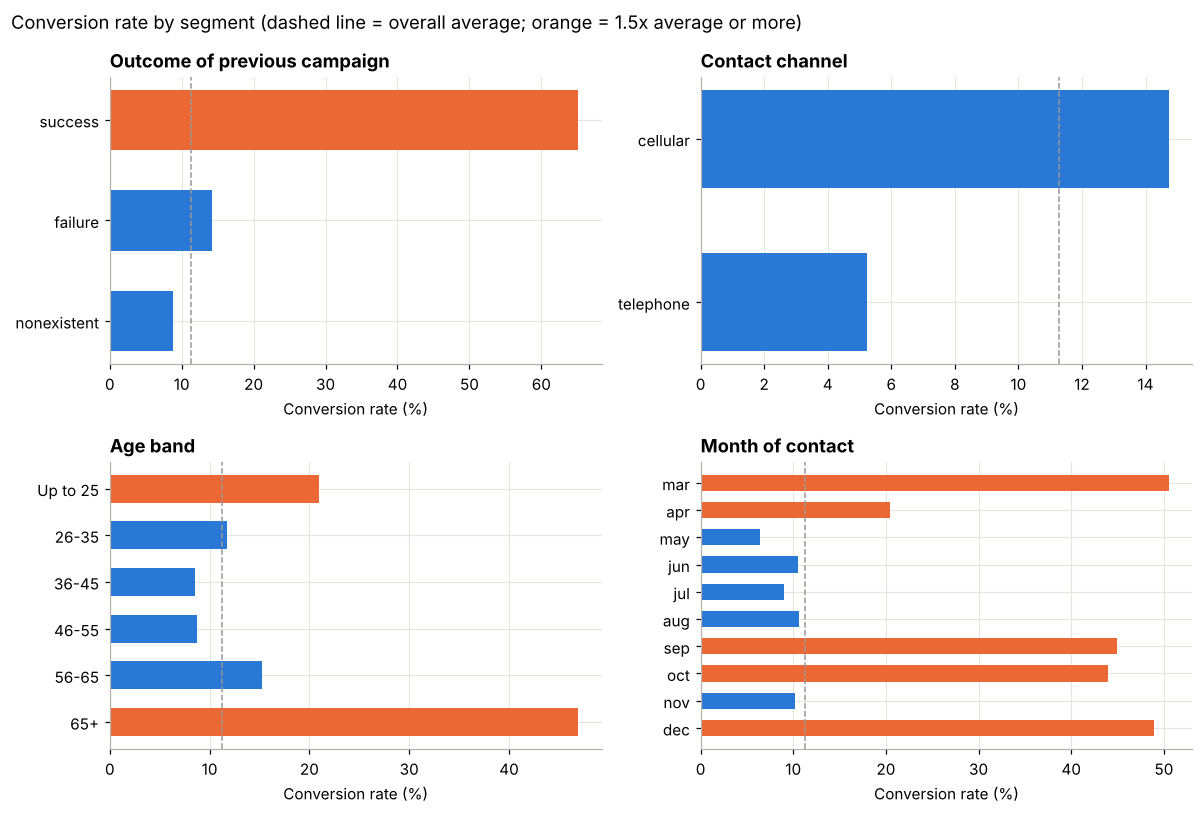

In [4]:
def conv_table(col):
    t = df.groupby(col, observed=True)["target"].agg(calls="size", conversions="sum", conv_rate="mean")
    t["lift_vs_avg"] = t["conv_rate"] / base_rate
    return t.sort_values("conv_rate", ascending=False)

def bar(ax, t, title):
    colors = [ORANGE if v > base_rate * 1.5 else BLUE for v in t["conv_rate"]]
    ax.barh(t.index.astype(str), t["conv_rate"] * 100, color=colors, height=0.6)
    ax.axvline(base_rate * 100, color=GREY, ls="--", lw=1)
    ax.set_title(title, loc="left", fontweight="bold"); ax.set_xlabel("Conversion rate (%)")
    ax.invert_yaxis()

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
bar(axes[0, 0], conv_table("poutcome"), "Outcome of previous campaign")
bar(axes[0, 1], conv_table("contact"), "Contact channel")
bar(axes[1, 0], conv_table("age_band").sort_index(), "Age band")
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
bar(axes[1, 1], conv_table("month").reindex(month_order), "Month of contact")
fig.suptitle("Conversion rate by segment (dashed line = overall average; orange = 1.5x average or more)", x=0.01, ha="left")
plt.tight_layout(); plt.savefig("charts/segments.png", bbox_inches="tight"); plt.show()

In [5]:
conv_table("poutcome")

,calls,conversions,conv_rate,lift_vs_avg
poutcome,,,,
success,1373,894,0.651129,5.779453
failure,4252,605,0.142286,1.262938
nonexistent,35551,3140,0.088324,0.783967


In [6]:
mt = conv_table("month").reindex(month_order)
mt["share_of_calls"] = mt["calls"] / mt["calls"].sum()
mt[["calls", "share_of_calls", "conv_rate", "lift_vs_avg"]]

,calls,share_of_calls,conv_rate,lift_vs_avg
month,,,,
mar,546,0.013260,0.505495,4.486795
apr,2631,0.063896,0.204865,1.818393
may,13767,0.334345,0.064357,0.571234
jun,5318,0.129153,0.105115,0.933003
jul,7169,0.174106,0.090389,0.802299
aug,6176,0.149990,0.106056,0.941356
sep,570,0.013843,0.449123,3.986437
oct,717,0.017413,0.439331,3.899520
nov,4100,0.099573,0.101463,0.900594


In [7]:
conv_table("job")

,calls,conversions,conv_rate,lift_vs_avg
job,,,,
student,875,275,0.314286,2.789616
retired,1718,434,0.252619,2.242262
unemployed,1014,144,0.142012,1.260504
admin.,10419,1351,0.129667,1.150930
management,2924,328,0.112175,0.995672
unknown,330,37,0.112121,0.995194
technician,6739,730,0.108325,0.961495
self-employed,1421,149,0.104856,0.930705
housemaid,1060,106,0.100000,0.887605


**Observations:**
- **Past success is the strongest signal.** Customers who said yes in the previous campaign convert at roughly 65%, about 6x the average.
- **Channel mix:** mobile (cellular) converts about 3x better than landline.
- **Timing:** May takes about a third of all calls but converts worst. March, September, October and December convert at 40-50% on very small volumes. Effort is concentrated in the weakest month.
- **Life stage:** under-25s (about 21%) and over-65s (about 47%) convert far above average, and by job, students and retirees lead. These are natural targets for a savings product.

### Call fatigue: does calling the same customer again help?

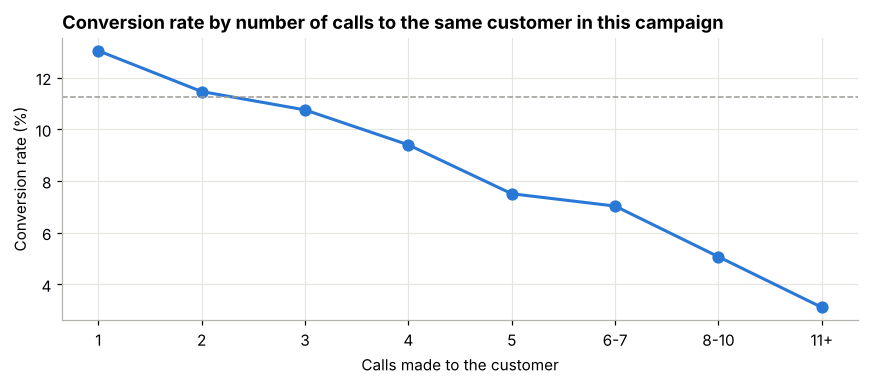

,calls,conversions,conv_rate,lift_vs_avg
calls_bucket,,,,
1,17634,2299,0.130373,1.157199
2,10568,1211,0.114591,1.017117
3,5340,574,0.107491,0.954092
4,2650,249,0.093962,0.834014
5,1599,120,0.075047,0.666120
6-7,1608,113,0.070274,0.623752
8-10,908,46,0.050661,0.449668
11+,869,27,0.031070,0.275781


In [8]:
df["calls_bucket"] = pd.cut(df["campaign"], [0, 1, 2, 3, 4, 5, 7, 10, 100],
                            labels=["1", "2", "3", "4", "5", "6-7", "8-10", "11+"])
fat = conv_table("calls_bucket").sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(fat.index.astype(str), fat["conv_rate"] * 100, color=BLUE, lw=2, marker="o", ms=7)
ax.axhline(base_rate * 100, color=GREY, ls="--", lw=1)
ax.set_title("Conversion rate by number of calls to the same customer in this campaign", loc="left", fontweight="bold")
ax.set_xlabel("Calls made to the customer"); ax.set_ylabel("Conversion rate (%)")
plt.tight_layout(); plt.savefig("charts/call_fatigue.png", bbox_inches="tight"); plt.show()
fat

Conversion falls steadily with every repeat call. By the 5th call it is down to about 7.5%, against 13% on the first call, and beyond 10 calls it is about 3%. **A contact cap of about 5 calls per customer** would free capacity for better prospects.

### Macro environment
The bank's conversion rate moves strongly with interest rates. When the 3-month Euribor rate was low (2009-10), customers were far more willing to lock money into deposits. In India the equivalent would be repo-rate cycles affecting FD demand.

In [9]:
df["euribor_band"] = pd.cut(df["euribor3m"], [0, 1.5, 4.0, 6.0], labels=["Low (<1.5%)", "Mid (1.5-4%)", "High (>4%)"])
conv_table("euribor_band").sort_index()

,calls,conversions,conv_rate,lift_vs_avg
euribor_band,,,,
Low (<1.5%),13212,3174,0.240236,2.132348
Mid (1.5-4%),296,127,0.429054,3.808306
High (>4%),27668,1338,0.048359,0.429238


## 3. Propensity model
**Setup:** predict `target` from information available *before* the call. `duration` is excluded. Split 75/25, stratified on the target.

Two models:
- **Logistic Regression**: an interpretable baseline (this is what most bank scorecards use)
- **Gradient Boosting** (HistGradientBoosting): captures non-linear effects and interactions

**Metric:** with an 11% positive rate, accuracy is misleading (predicting "no" for everyone gives 89%). I use **ROC-AUC** (ranking quality), **PR-AUC** (precision on the rare class) and, most importantly for the business, **lift / capture by decile**.

In [10]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
num_cols = ["age", "campaign", "previous", "prev_contacted", "emp.var.rate", "cons.price.idx",
            "cons.conf.idx", "euribor3m", "nr.employed"]
X, y = df[cat_cols + num_cols], df["target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                         ("num", StandardScaler(), num_cols)])
models = {
    "Logistic Regression": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Gradient Boosting": Pipeline([("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                                                               ("num", "passthrough", num_cols)])),
                                   ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                                          l2_regularization=1.0, random_state=42))]),
}
scores, results = {}, []
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    scores[name] = p
    results.append({"model": name, "ROC_AUC": roc_auc_score(y_te, p), "PR_AUC": average_precision_score(y_te, p)})
res = pd.DataFrame(results).set_index("model").round(3)
print(f"Random-guess PR-AUC baseline = {y_te.mean():.3f}")
res

Random-guess PR-AUC baseline = 0.113


,ROC_AUC,PR_AUC
model,,
Logistic Regression,0.802,0.444
Gradient Boosting,0.815,0.491


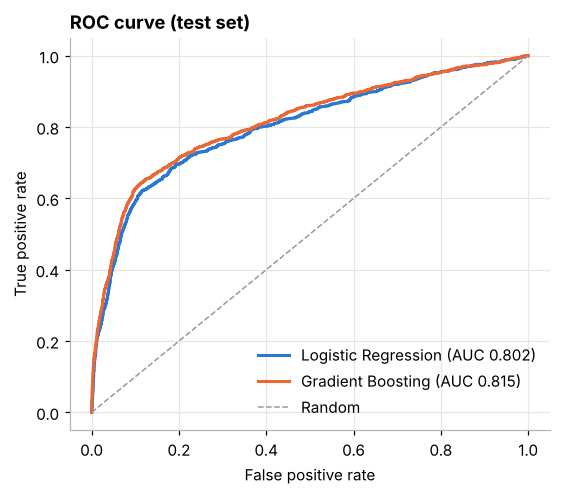

In [11]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for (name, p), c in zip(scores.items(), [BLUE, ORANGE]):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Random")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curve (test set)", loc="left", fontweight="bold"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("charts/roc.png", bbox_inches="tight"); plt.show()

## 4. Gains table: how well does the score rank customers?
Sort test-set customers by predicted probability, cut them into 10 equal groups (deciles), and check the actual conversion in each.

In [12]:
best_name = res["ROC_AUC"].idxmax()
p_best = scores[best_name]
g = pd.DataFrame({"p": p_best, "y": y_te.values}).sort_values("p", ascending=False).reset_index(drop=True)
g["decile"] = pd.qcut(g.index, 10, labels=range(1, 11))
gains = g.groupby("decile", observed=True).agg(customers=("y", "size"), conversions=("y", "sum"),
                                               avg_score=("p", "mean"))
gains["conv_rate"] = gains["conversions"] / gains["customers"]
gains["lift"] = gains["conv_rate"] / g["y"].mean()
gains["cum_capture"] = gains["conversions"].cumsum() / gains["conversions"].sum()
print("Model used:", best_name)
gains.round(3)

Model used: Gradient Boosting


,customers,conversions,avg_score,conv_rate,lift,cum_capture
decile,,,,,,
1,1030,540,0.497,0.524,4.652,0.466
2,1029,233,0.199,0.226,2.009,0.666
3,1029,89,0.086,0.086,0.768,0.743
4,1030,55,0.068,0.053,0.474,0.791
5,1029,63,0.060,0.061,0.543,0.845
6,1029,44,0.054,0.043,0.379,0.883
7,1030,40,0.047,0.039,0.345,0.917
8,1029,36,0.040,0.035,0.310,0.948
9,1029,30,0.034,0.029,0.259,0.974


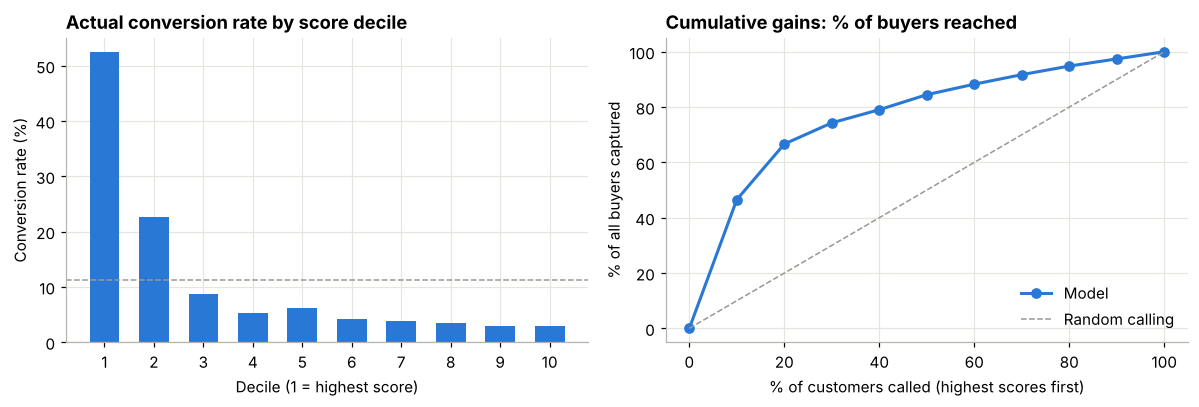

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(gains.index.astype(str), gains["conv_rate"] * 100, color=BLUE, width=0.6)
axes[0].axhline(g["y"].mean() * 100, color=GREY, ls="--", lw=1)
axes[0].set_title("Actual conversion rate by score decile", loc="left", fontweight="bold")
axes[0].set_xlabel("Decile (1 = highest score)"); axes[0].set_ylabel("Conversion rate (%)")
x = np.arange(0, 11) * 10
axes[1].plot(x, np.r_[0, gains["cum_capture"].values] * 100, color=BLUE, lw=2, marker="o", ms=6, label="Model")
axes[1].plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="Random calling")
axes[1].set_title("Cumulative gains: % of buyers reached", loc="left", fontweight="bold")
axes[1].set_xlabel("% of customers called (highest scores first)"); axes[1].set_ylabel("% of all buyers captured")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("charts/gains.png", bbox_inches="tight"); plt.show()

## 5. What drives propensity?
Permutation importance: how much the model's AUC drops when each feature is randomly shuffled.

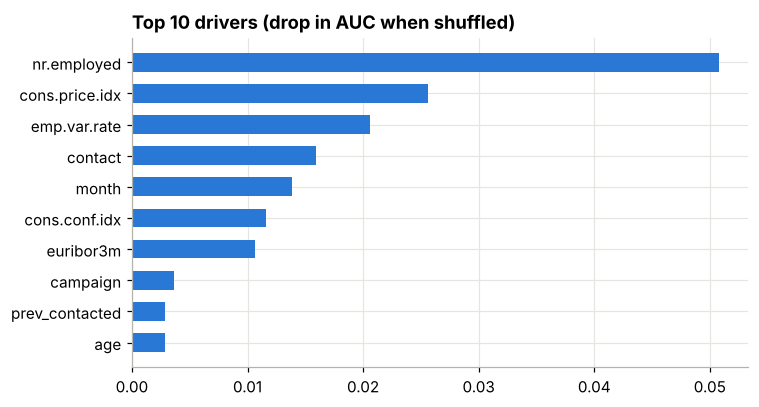

,0
nr.employed,0.0508
cons.price.idx,0.0256
emp.var.rate,0.0206
contact,0.0159
month,0.0139
cons.conf.idx,0.0116
euribor3m,0.0107
campaign,0.0036
prev_contacted,0.0029
age,0.0028


In [14]:
pi = permutation_importance(models[best_name], X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index[::-1], imp.values[::-1], color=BLUE, height=0.6)
ax.set_title("Top 10 drivers (drop in AUC when shuffled)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("charts/drivers.png", bbox_inches="tight"); plt.show()
imp.round(4)

**Reading the drivers:** the macro indicators (employment, inflation, interest rates) dominate. *When* the bank runs a campaign matters as much as *who* it calls. Next come contact channel, month and the number of calls already made. Past campaign outcome adds less here because it overlaps with the `prev_contacted` flag and the macro period.

## 6. Campaign economics: who should we call?
**Illustrative unit economics** (assumptions, easy to change):
- Cost per call (agent time and telephony): **Rs 60**
- Net value of one term-deposit sale (expected net interest margin over its life): **Rs 1,200**

Compare three strategies on the test set: call everyone (the current approach), call the top-scored X%, and the profit-maximising X%.

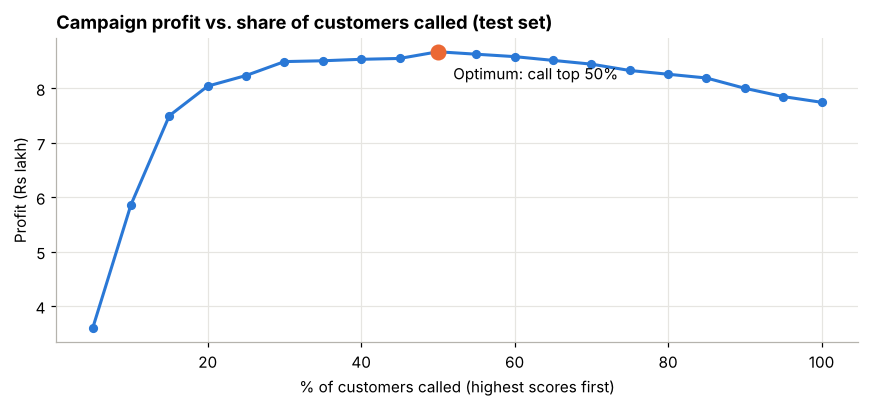

,calls,sales,capture,conv_rate,profit,profit_uplift_vs_everyone
Call everyone,10294.0,1160.0,1.000,0.113,774360.0,0.000
Call top 30%,3088.0,862.0,0.743,0.279,849120.0,0.097
Call top 50% (optimal),5147.0,980.0,0.845,0.190,867180.0,0.120


In [15]:
COST_PER_CALL, VALUE_PER_SALE = 60, 1200
n, buyers = len(g), g["y"].sum()
rows = []
for pct in range(5, 101, 5):
    k = int(round(n * pct / 100))
    sales = g["y"].iloc[:k].sum()
    rows.append({"pct_called": pct, "calls": k, "sales": sales, "capture": sales / buyers,
                 "conv_rate": sales / k, "profit": sales * VALUE_PER_SALE - k * COST_PER_CALL})
curve = pd.DataFrame(rows).set_index("pct_called")
opt = curve["profit"].idxmax()
everyone, top30 = curve.loc[100], curve.loc[30]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(curve.index, curve["profit"] / 1e5, color=BLUE, lw=2, marker="o", ms=5)
ax.scatter([opt], [curve.loc[opt, "profit"] / 1e5], s=90, color=ORANGE, zorder=3)
ax.annotate(f"Optimum: call top {opt}%", (opt, curve.loc[opt, "profit"] / 1e5), xytext=(10, -18), textcoords="offset points")
ax.set_title("Campaign profit vs. share of customers called (test set)", loc="left", fontweight="bold")
ax.set_xlabel("% of customers called (highest scores first)"); ax.set_ylabel("Profit (Rs lakh)")
plt.tight_layout(); plt.savefig("charts/profit_curve.png", bbox_inches="tight"); plt.show()

summary = pd.DataFrame({
    "Call everyone": everyone, "Call top 30%": top30, f"Call top {opt}% (optimal)": curve.loc[opt]
}).T[["calls", "sales", "capture", "conv_rate", "profit"]]
summary["profit_uplift_vs_everyone"] = summary["profit"] / everyone["profit"] - 1
summary.round(3)

In [16]:
print(f"Calling only the top 30% of scored customers reaches {top30['capture']:.0%} of all buyers "
      f"with {1 - top30['calls'] / everyone['calls']:.0%} fewer calls.")
print(f"Conversion rate rises from {everyone['conv_rate']:.1%} to {top30['conv_rate']:.1%} "
      f"({top30['conv_rate'] / everyone['conv_rate']:.1f}x).")
print(f"Profit-optimal depth is the top {opt}%: profit {curve.loc[opt, 'profit'] / everyone['profit'] - 1:+.0%} vs calling everyone.")

Calling only the top 30% of scored customers reaches 74% of all buyers with 70% fewer calls.
Conversion rate rises from 11.3% to 27.9% (2.5x).
Profit-optimal depth is the top 50%: profit +12% vs calling everyone.


## 7. Recommendations
1. **Score before you dial.** Use the propensity model to rank the base and call only the top 30-50%. Calling the top 30% reaches about 74% of buyers with 70% fewer calls. Under the assumed economics, the top 50% maximises profit (about +12% vs calling everyone).
2. **Prioritise past responders.** Customers who bought last time convert at about 65%. Run a dedicated re-engagement list for them.
3. **Shift channel mix to mobile.** Cellular converts about 3x landline. Update contact data and default to mobile.
4. **Fix campaign timing.** Move volume out of May into the higher-converting months, and test before scaling.
5. **Cap contact attempts at about 5 per customer** to cut wasted effort and customer irritation.
6. **Tailor the offer by life stage.** Students and retirees over-index strongly, so create savings-focused messaging for these segments.
7. **Re-time campaigns around the rate cycle.** Demand for deposits is highest when market rates fall. Plan budget around rate expectations.

**Limitations and next steps:** the data is 2008-10 Portugal, so the patterns need validating on Indian data. A random split can mix time periods, so validate on a later time window (out-of-time test) before deployment. The economics are illustrative assumptions. A natural next step is an **uplift model** that targets people the call actually *persuades*, not just people likely to buy anyway.